# Exercise 4


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8")
plt.rcParams.update({"image.cmap": "viridis"})

**Linear Regression**

The goal of this exercise is to explore a simple linear regression problem based on Portugese white wine.

The dataset is based on
Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis. **Modeling wine preferences by data mining from physicochemical properties**. Published in Decision Support Systems, Elsevier, 47(4):547-553, 2009.



In [12]:
# The code snippet below is responsible for downloading the dataset
# - for example when running via Google Colab.
#
# You can also directly download the file using the link if you work
# with a local setup (the !wget command will work either way assuming
# you are on a unix-based machine and have wget installed)
!wget -nc https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv

File ‘winequality-white.csv’ already there; not retrieving.



Note: The code was run in vs code and saved on my github. The download using the link above did not seem to work, thus the modification when downloading the data.

In [13]:
import urllib.request

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

urllib.request.urlretrieve(url, "winequality-white.csv")

('winequality-white.csv', <http.client.HTTPMessage at 0x7a6f74d1ec40>)

In [14]:
df = pd.read_csv("winequality-white.csv", sep=";")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


**Before we start**

The downloaded file contains data on 4989 wines. For each wine 11 features are recorded (column 0 to 10). The final columns contains the quality of the wine. This is what we want to predict. More information on the features and the quality measurement is provided in the original publication.

List of columns/features:
0. fixed acidity
1. volatile acidity
2. citric acid
3. residual sugar
4. chlorides
5. free sulfur dioxide
6. total sulfur dioxide
7. density
8. pH
9. sulphates
10. alcohol
11. quality



[file]: https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv

In [15]:
# Before working with the data,
# we download and prepare all features

# load all examples from the file
data = np.genfromtxt('winequality-white.csv',delimiter=";",skip_header=1)

print(f"{data.shape = }")

# Prepare for proper training
rng = np.random.default_rng(1234)
rng.shuffle(data)  # randomly sort examples

# take the first 3000 examples for training
# (remember array slicing from last week)
X_train = data[:3000, :11]  # all features except last column
y_train = data[:3000, 11]  # quality column

# and the remaining examples for testing
X_test = data[3000:, :11]  # all features except last column
y_test = data[3000:, 11]  # quality column

print("First example:")
print("Features:", X_train[0])
print("Quality:", y_train[0])

data.shape = (4898, 12)
First example:
Features: [6.8000e+00 1.9000e-01 7.1000e-01 1.7500e+01 4.2000e-02 2.1000e+01
 1.1400e+02 9.9784e-01 2.8500e+00 5.0000e-01 9.5000e+00]
Quality: 6.0


# Problems


* First we want to understand the data better. Plot (`plt.hist`) the distribution of each of the features for the training data as well as the 2D distribution (either `plt.scatter` or `plt.hist2d`) of each feature versus quality. Also calculate the correlation coefficient (`np.corrcoef`) for each feature with quality. Which feature by itself seems most predictive for the quality?

* Calculate the linear regression weights. Numpy provides functions for matrix multiplication (`np.matmul`), matrix transposition (`.T`) and matrix inversion (`np.linalg.inv`).

* Use the weights to predict the quality for the test dataset. How
does your predicted quality compare with the true quality of the test data? Calculate the correlation coefficient between predicted and true quality and draw a scatter plot.

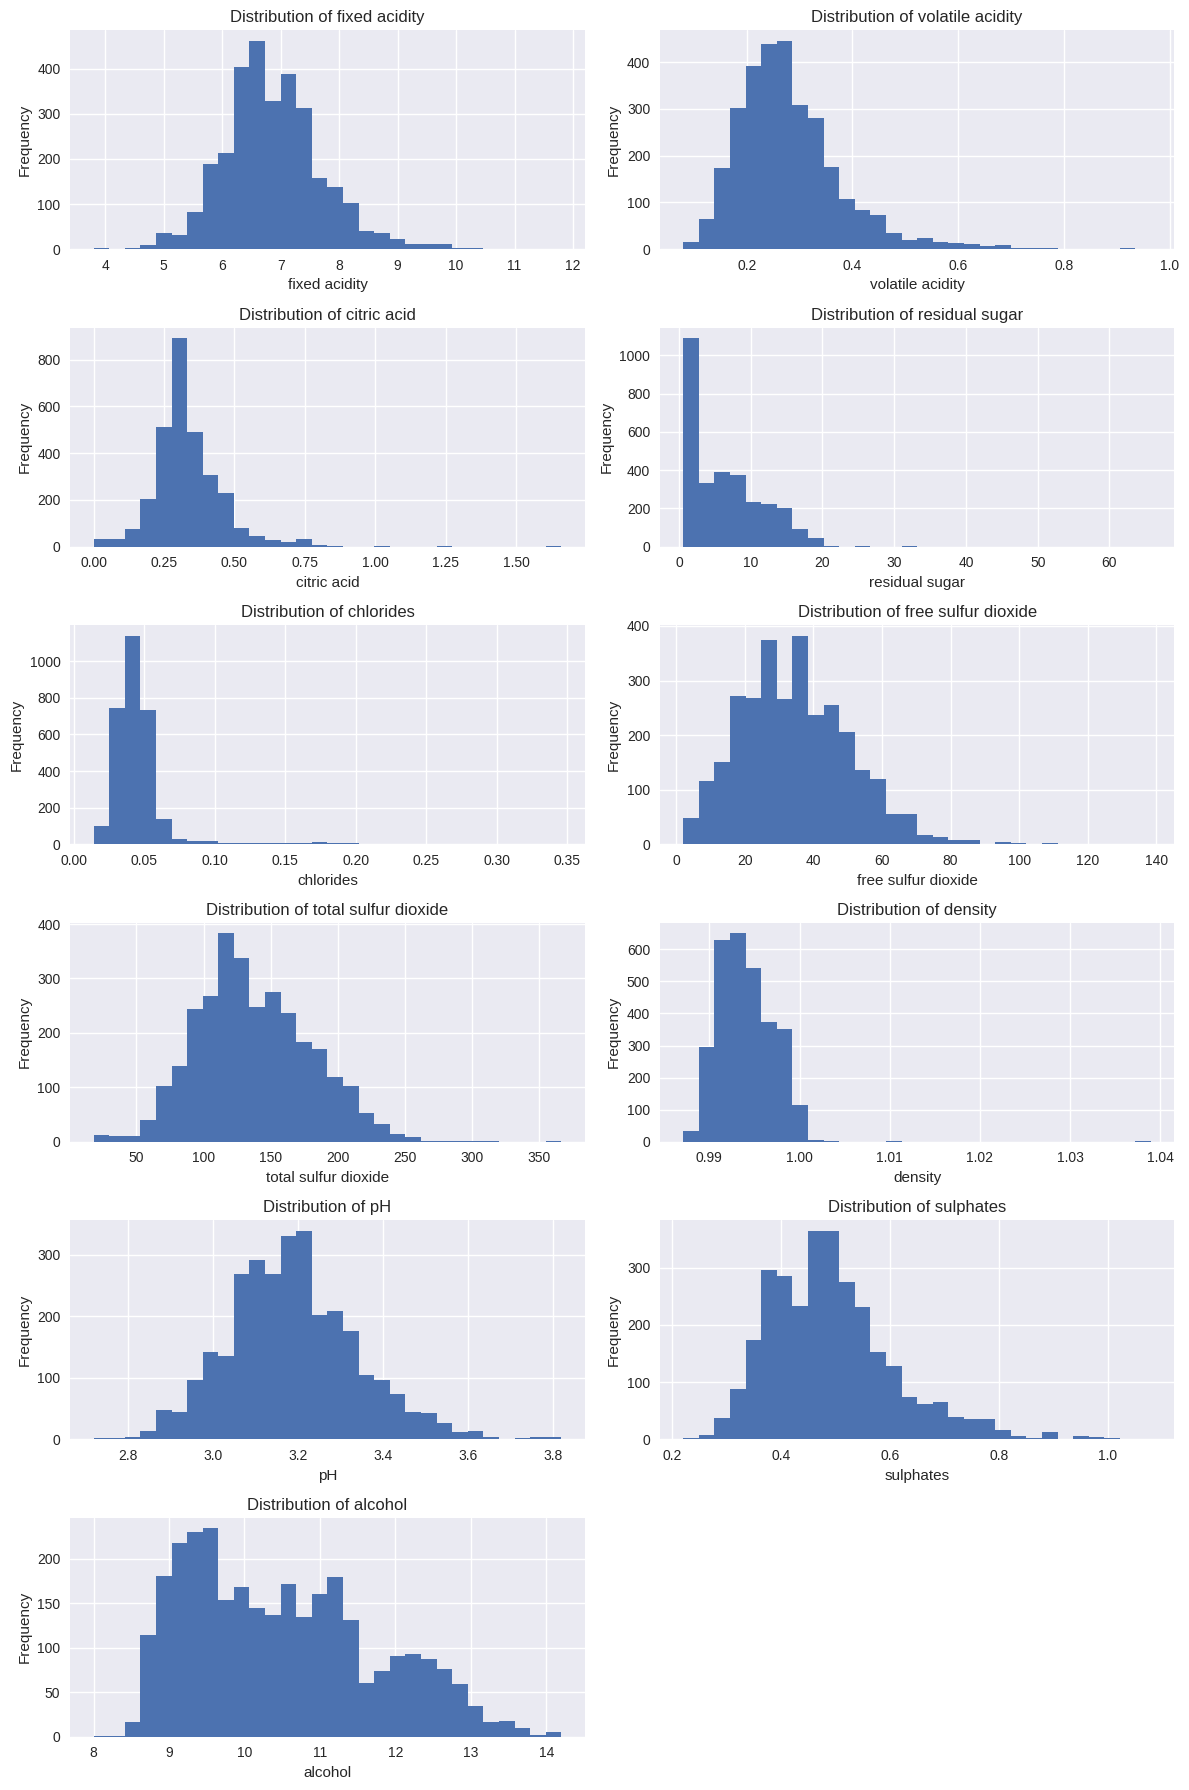

In [16]:
# plot the distribution of each of the features in the training set (using histograms)

feature_names = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol"
]


fig, axes = plt.subplots(6, 2, figsize=(12, 18))
axes = axes.flatten()

for i in range(11):
    axes[i].hist(X_train[:, i], bins=30)
    axes[i].set_xlabel(feature_names[i])
    axes[i].set_ylabel("Frequency")
    axes[i].set_title(f"Distribution of {feature_names[i]}")

# Hide the unused 12th subplot
axes[11].axis("off")

plt.tight_layout()
plt.show()


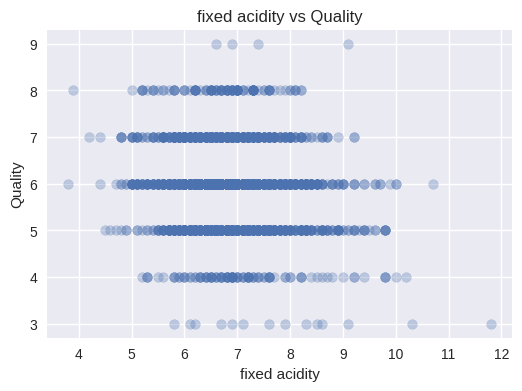

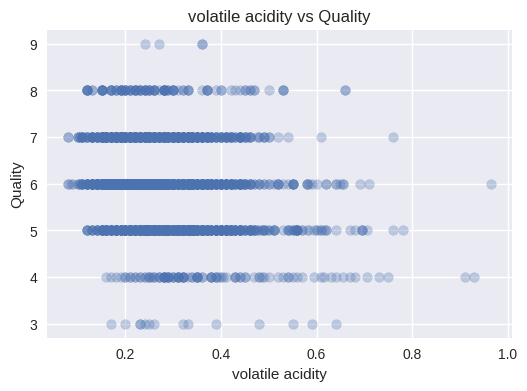

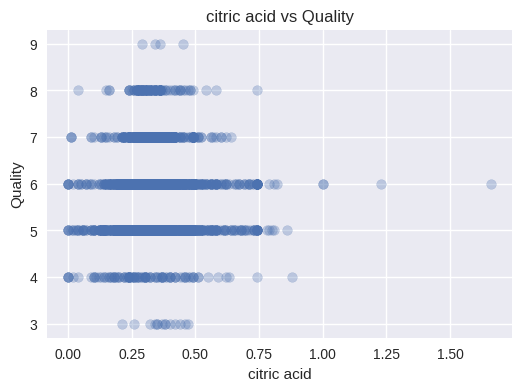

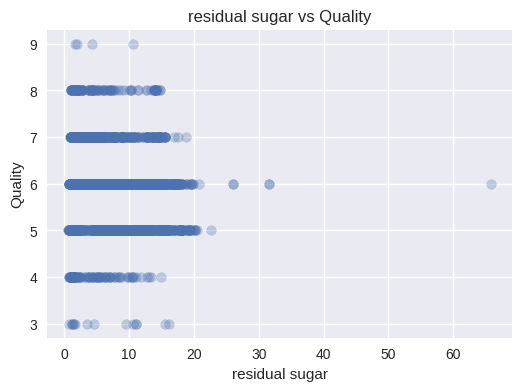

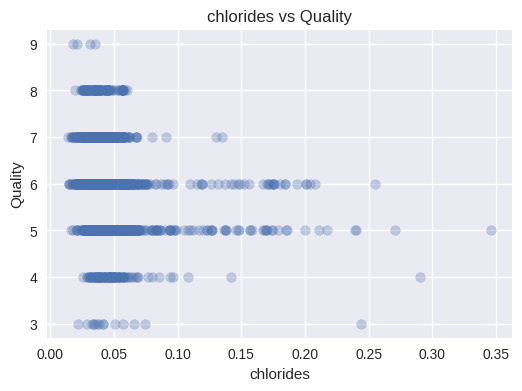

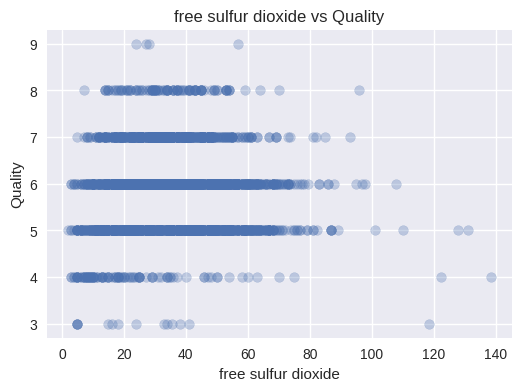

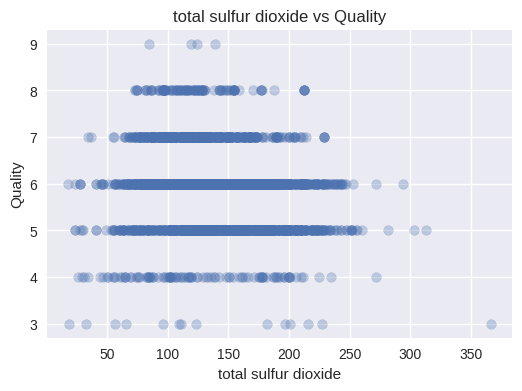

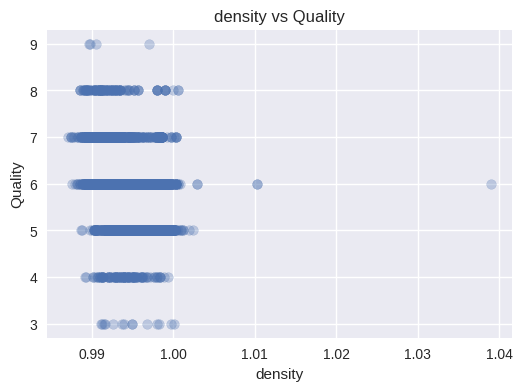

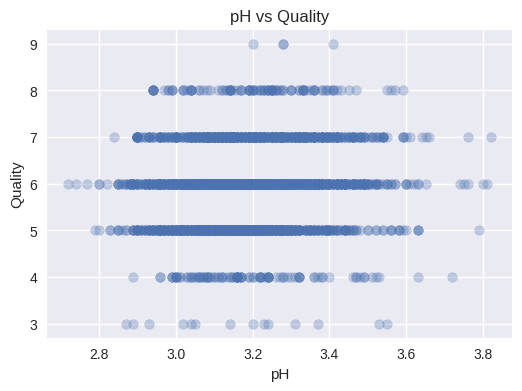

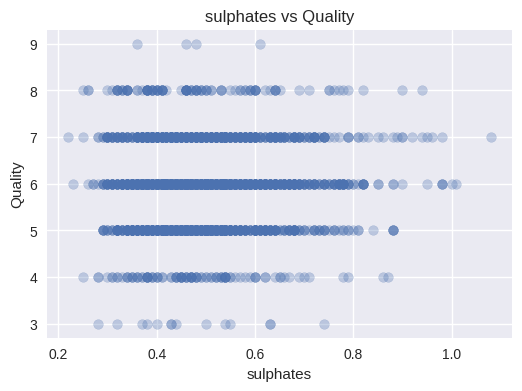

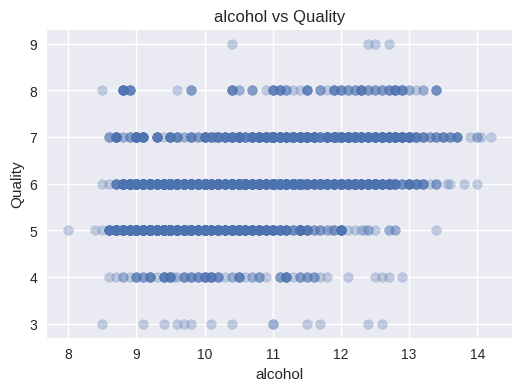

In [7]:
# Plot the 2D distribution of each feature against the quality of the wine (using scatter plots)
for i in range(11):
    plt.figure(figsize=(6, 4))

    plt.scatter(X_train[:, i], y_train, alpha=0.3)

    plt.xlabel(feature_names[i])
    plt.ylabel("Quality")
    plt.title(f"{feature_names[i]} vs Quality")

    plt.show()

In [8]:
# calculate the correlation coefficient (`np.corrcoef`) for each feature with quality
correlations = []
for i in range(11):
    corr = np.corrcoef(X_train[:, i], y_train)[0, 1]
    correlations.append(corr)

# display the correlation coefficients
for i, corr in enumerate(correlations):
    print(f"Correlation between {feature_names[i]} and Quality: {corr:.3f}")

Correlation between fixed acidity and Quality: -0.128
Correlation between volatile acidity and Quality: -0.207
Correlation between citric acid and Quality: -0.007
Correlation between residual sugar and Quality: -0.095
Correlation between chlorides and Quality: -0.210
Correlation between free sulfur dioxide and Quality: 0.018
Correlation between total sulfur dioxide and Quality: -0.172
Correlation between density and Quality: -0.300
Correlation between pH and Quality: 0.104
Correlation between sulphates and Quality: 0.052
Correlation between alcohol and Quality: 0.429


1. The correlelation tells us how strongly the feature is linearly related to quality.
Positive correlation: higher feature values --> higher quality
Negative correlation: Higher feature values --> lower quality
Correlation close to zero --> litle linear relation

    Thus acording to the correlation the alcohol has a larger correlation with quality. Meaning the higher the alcohol the better the quality. Density also seems to have an impact with quality. Namely the lower the density the better the qulaity seems to be due to the negative sign.

Next we calculate the linear regression weights. Numpy provides functions for matrix multiplication (`np.matmul`), matrix transposition (`.T`) and matrix inversion (`np.linalg.inv`).

Done by computing

$$
\overrightarrow{\mathbf{w}}=\left(\mathbf{X}^{T} \mathbf{X}\right)^{-1} \mathbf{X}^{T} \overrightarrow{\mathbf{y}}
$$

In [9]:
# compute the linear regression weights
w = np.linalg.inv(X_train.T @ X_train) @ X_train.T @ y_train

We then use the weights to predict the quality for the test dataset. How
does your predicted quality compare with the true quality of the test data? Calculate the correlation coefficient between predicted and true quality and draw a scatter plot.

Correlation coefficient: 0.5158643603522332


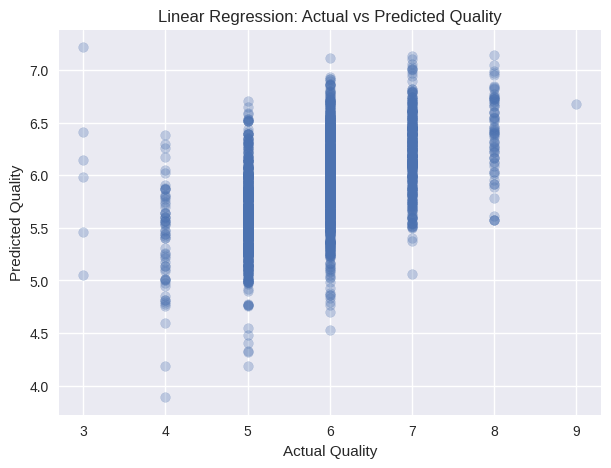

In [10]:
# Use the weights to predict the quality of the wines in the test set
y_pred = X_test @ w

# Calculate the correlation coefficient between the predicted and actual quality values in the test set
test_correlation = np.corrcoef(y_pred, y_test)[0, 1]
print("Correlation coefficient:", test_correlation)

# Draw a scatter plot of the predicted quality values against the actual quality values in the test set
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Actual Quality")
plt.ylabel("Predicted Quality")
plt.title("Linear Regression: Actual vs Predicted Quality")
plt.show()

The correlation between the true quality and predicted quality is 0.516. If it is close to 1 this indicates a strong correlation while if it is close to zeros the correlation is weak. In this case the correlation was somewhere in the midle. This can be illustraded also in the scatter plot. The scatter plot shows a positive relationship between predicted and actual quality, although the predictions do not perfectly match the true values. This suggests that the model can capture some of the variation in wine quality but is not completely accurate.

**Homework Submission**

When you submit your exercise sheet, please alwasy do two things

1) Generate a PDF of your iPython notebook. Submit this PDF through Studium (Uppsala)/Moodle (Dortmund).

2) Provide a link to your google colab notebook so that we can directly execute and test your code. To do that click on "share", change access to "anyone with the link", copy the link and add it as a comment to your submission on Studium (Uppsala)/Moodle (Dortmund).

# Hints

Formally, we want to find weights $w_i$ that minimize:
$$
\sum_{j}\left(\sum_{i} X_{i j} w_{i}-y_{j}\right)^{2}
$$
The index $i$ denotes the different features (properties of the wines) while the index $j$ runs over the different wines. The matrix $X_{ij}$ contains the training data, $y_j$ is the 'true' quality for sample $j$. The weights can be found by taking the first derivative of the above expression with respect to the weights and setting it to zero (the standard strategy for finding an extremum), and solving the corresponding system of equations (for a detailed derivation, see [here](https://en.wikipedia.org/wiki/Ordinary_least_squares)). The result is:
$$
\overrightarrow{\mathbf{w}}=\left(\mathbf{X}^{T} \mathbf{X}\right)^{-1} \mathbf{X}^{T} \overrightarrow{\mathbf{y}}
$$

In the end, you should have as many components of $w_i$ as there are features in the data (i.e. eleven in this case).

You can use `.shape` to inspect the dimensions of numpy tensors.
